# **Pocket2Mol: De Novo Drug Design by Efficient Molecular Sampling Based on 3D Protein Pockets using E(3)-equivariant generative neural networks**

Generation of 3D drug-like molecules for protein pockets is
a significant but challenging task. In this work, we use
Pocket2Mol, an E(3)-equivariant generative network composed of a graph neural network to model the chemical and
geometrical features of the 3D protein pockets and a new
efficient algorithm to sample new 3D drug candidates conditioned on the pockets. Experiments have demonstrated that
molecules generated by Pocket2Mol not only show better
affinities and chemical properties but also contain more realistic and accurate structures.

### **How this model works**
This notebook runs **Pocket2Mol**, a geometric deep learning model that invents new molecules to fit into a specific protein pocket. It works in three steps:

1.  **Read the Pocket:** It analyzes the 3D coordinates of your target protein atoms using an **Equivariant Graph Neural Network (GNN)**. This ensures the model understands the shape of the pocket regardless of how the protein is rotated.
2.  **Find the Center:** It identifies the center of the binding pocket (usually based on a known ligand) to focus its generation.
3.  **Build Atom-by-Atom:** It constructs the new molecule step-by-step:
    * **Position:** Predicts *where* the next atom should be (X, Y, Z coordinates).
    * **Element:** Decides *what* atom it is (C, N, O, etc.).
    * **Bond:** Connects it to the existing structure.

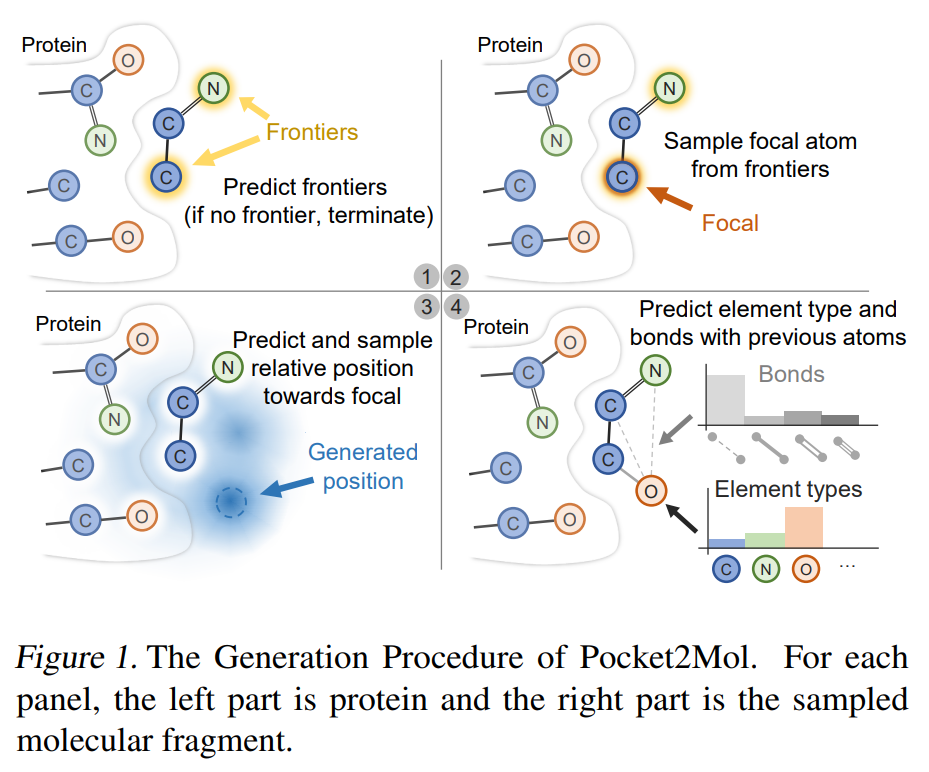

##What are E(3)-Equivariant Generative Networks?

In simple terms: It is a neural network that understands 3D physics. It guarantees that if you rotate or move your protein pocket, the molecule it invents will rotate or move exactly along with it.

**1. What is E(3)?**
E(3) stands for the Euclidean Group in 3 Dimensions. It refers to the three specific ways you can transform an object in 3D space without changing its shape or size:

1. Translation: Moving it (shifting X, Y, Z).
2. Rotation: Spinning it around an axis.
3. Reflection: Flipping it (like in a mirror).

**Equivariance vs. Invariance**

* To understand Equivariance, you must distinguish it from Invariance.

* Invariance (Standard Models): The output stays the same regardless of rotation.

* Example: If you input a molecule and ask "Is this toxic?", the answer should be "Yes" whether the molecule is upright, upside down, or sideways. The rotation doesn't change the toxicity.

* *Equivariance (Generative Models): The output changes in the exact same way the input changed.*

* Example: If you input a protein pocket and ask "Where should the Carbon atom go?", the answer is a coordinate (X, Y, Z).

* If you rotate the protein 90 degrees, the "correct spot" for the Carbon atom must also rotate 90 degrees.

The Mathematical Definition:
If $f$ is your neural network and $R$ is a rotation: $$f(Rotate(Input)) = Rotate(f(Input))$$


**3. Why is this critical for Pocket2Mol?**

* Standard neural networks do not inherently understand 3D space. They see coordinates like [1.0, 0.0, 0.0] just as a list of numbers.

* If you trained a non-equivariant model:

1. You feed it a protein. It places a Carbon atom at [1, 1, 1].

2. You rotate the protein 180 degrees.

3. The model, getting different numbers now, might get confused and place the Carbon atom at [5, 0, 0]—totally outside the pocket.


**With an E(3)-Equivariant model:**

* The model uses geometric vectors rather than just lists of numbers.

* If you rotate the protein, the model's internal math rotates with it.

* The generated molecule is always placed correctly relative to the pocket, regardless of how the PDB file was oriented.



**Summary**

In the context of the TeachOpenCADD tutorial and Pocket2Mol:

* It ensures consistency: You don't need to "align" or "center" your data perfectly for the model to work.

* It creates valid chemistry: The model understands that atoms have specific geometric relationships (angles and distances) that must be preserved even if the whole system spins.

* It is data efficient: The model doesn't need to see the same protein rotated 1,000 different ways during training to learn what "rotation" is. It knows geometry by design.

##References

Paper Source:
https://arxiv.org/abs/2205.07249
http://proceedings.mlr.press/v162/peng22b/peng22b.pdf

Review: https://liner.com/review/pocket2mol-efficient-molecular-sampling-based-on-3d-protein-pockets

An introduction to E(3)-invariant graph neural networks:
https://projects.volkamerlab.org/teachopencadd/talktorials/T036_e3_equivariant_gnn.html

# Use Pocket2Mol to generate molecules

### **Step 1: Define Inputs**
Here we define the target protein and the reference ligand.
* **PDB_ID:** The 4-letter code for your protein structure from the RCSB database.
* **LIG_ID:** The 3-letter code for the ligand inside that protein. We use this ligand *only* to find where the pocket is located.

In [ ]:
#@title PDB + SMILES input

PDB_ID = '7NN0' #@param {type:"string"}
LIG_ID = 'ANP' #@param {type:"string"}
CHAIN = 'D' #@param {type:"string"}

# markdown Download a tar file containing all results?
# download_results = True #@param {type:"boolean"}

## Install prerequisites

In [ ]:
!pip install ipython-autotime --quiet
%load_ext autotime
!pip install rdkit biopython pyyaml easydict tensorboard lmdb gdown prody pypdb --quiet #  replaced python-lmdb with lmdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.4/36.4 MB 63.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 111.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.4/299.4 kB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.5/37.5 MB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 103.1/103.1 kB 10.3 MB/s eta 0:00:00
time: 10.7 s (started: 2025-12-14 17:30:58 +00:00)


This code cell is setting up your environment by installing several crucial libraries for working with Graph Neural Networks, particularly those used by the Pocket2Mol model.

In [ ]:
import torch
print(f"torch version {torch.__version__}")
!pip install torch-cluster -f https://data.pyg.org/whl/torch-{torch.__version__}.html # This installs torch-cluster, a crucial dependency for PyTorch Geometric, optimized for efficient graph operations. The -f flag ensures it's compatible with your specific PyTorch version
!pip install torch-scatter -f https://data.pyg.org/whl/torch-{torch.__version__}.html # This command installs torch-scatter, another vital component for handling scattered data operations within graph neural networks. Like torch-cluster, it's version-locked to your PyTorch installation.
!pip install git+https://github.com/pyg-team/pytorch_geometric.git  --quiet #This directly installs the pytorch_geometric library from its GitHub repository, ensuring you get the most up-to-date version of this powerful graph neural network framework.

torch version 2.9.0+cu126
Looking in links: https://data.pyg.org/whl/torch-2.9.0+cu126.html
  Using cached torch_cluster-1.6.3.tar.gz (54 kB)
  Preparing metadata (setup.py) ... done
  Created wheel for torch-cluster: filename=torch_cluster-1.6.3-cp312-cp312-linux_x86_64.whl size=2205989 sha256=a9dd0a9c73570b667e36cdc21fb6671a11e64b324294a883eef573d5629d9a65
  Stored in directory: /root/.cache/pip/wheels/2e/8f/d0/13408a84825c9a587151a74727b4a6d47ec67e0d625b385ad7
Successfully built torch-cluster
Looking in links: https://data.pyg.org/whl/torch-2.9.0+cu126.html
  Using cached torch_scatter-2.1.2.tar.gz (108 kB)
  Preparing metadata (setup.py) ... done
  Created wheel for torch-scatter: filename=torch_scatter-2.1.2-cp312-cp312-linux_x86_64.whl size=3857036 sha256=2d597f20c51c21240c8c2894ecb867c8feceab6d70c672cad0c64ae3164933e7
  Stored in directory: /root/.cache/pip/wheels/84/20/50/44800723f57cd798630e77b3ec83bc80bd26a1e3dc3a672ef5
Successfully built torch-scatter
  Installing build depe


## Install Pocket2Mol

In [ ]:
!git clone https://github.com/pengxingang/Pocket2Mol --quiet

time: 405 ms (started: 2025-12-14 20:13:31 +00:00)


This code cell downloads the necessary datasets for the Pocket2Mol model to work.

These files constitute the CrossDocked2020 dataset, which is the standard benchmark for training and testing this model.



*   `crossdocked_pocket10.tar.gz:` This is the main database. It contains thousands of 3D structures of protein-ligand pairs. The "pocket10" in the name suggests these are pre-processed versions where the protein pockets have been extracted (likely within 10 Angstroms of the ligand) to make them ready for the neural network.
*   `split_by_name.pt:` This is a PyTorch data file. It tells the model which proteins to use for Training (learning), Validation (tuning), and Testing (final evaluation). It is called "split by name" because it ensures that the test set contains unique proteins that are not similar to those in the training set, preventing the model from "cheating" by memorizing shapes it has seen before.



In [ ]:
%cd /content/Pocket2Mol/data
!test -f crossdocked_pocket10.tar.gz || gdown 10KGuj15mxOJ2FBsduun2Lggzx0yPreEU && tar -xzf crossdocked_pocket10.tar.gz
!test -f split_by_name.pt || gdown 1mycOKpphVBQjxEbpn1AwdpQs8tNVbxKY
!ls -l

/content/Pocket2Mol/data
total 1637396
drwxr-xr-x 2465 1001 1001     118784 Apr 15  2021 crossdocked_pocket10
-rw-r--r--    1 root root 1616333272 Apr 15  2021 crossdocked_pocket10.tar.gz
-rw-r--r--    1 root root   44921289 May 30  2022 pretrained_Pocket2Mol.pt
-rw-r--r--    1 root root        837 Dec 14 18:08 README.md
-rw-r--r--    1 root root   15284527 Jan 19  2022 split_by_name.pt
-rw-r--r--    1 root root      12617 Dec 14 18:08 test_list.tsv
time: 48.3 s (started: 2025-12-14 20:13:33 +00:00)


This code cell downloads the "brain" of the AI model—the pre-trained weights file.

In [ ]:
# Create directory if it doesn't exist
!mkdir -p /content/Pocket2Mol/ckpt
%cd /content/Pocket2Mol/ckpt
# Download weights if not present
!test -f pretrained_Pocket2Mol.pt || gdown 1WaoEj9RDG4VEcyHEmgsjbh958txm1W6x
!ls -l

/content/Pocket2Mol/ckpt
Downloading...
From (original): https://drive.google.com/uc?id=1WaoEj9RDG4VEcyHEmgsjbh958txm1W6x
From (redirected): https://drive.google.com/uc?id=1WaoEj9RDG4VEcyHEmgsjbh958txm1W6x&confirm=t&uuid=da73ff19-fdc4-4c62-991d-f114afed88b2
To: /content/Pocket2Mol/ckpt/pretrained_Pocket2Mol.pt
100% 44.9M/44.9M [00:00<00:00, 136MB/s]
total 43876
-rw-r--r-- 1 root root 44921289 May 30  2022 pretrained_Pocket2Mol.pt
-rw-r--r-- 1 root root      309 Dec 14 18:08 README.md
time: 2.52 s (started: 2025-12-14 20:18:02 +00:00)


### **Step 2: Prepare the Pocket**
The model needs to know the exact center of the binding pocket to start generating molecules.
1.  **Download:** We fetch the PDB file and split it into two files: one for the protein and one for the reference ligand.
2.  **Calculate Center:** We read the reference ligand's file and calculate the mathematical average (mean) of its coordinates. This `[x, y, z]` point becomes the starting seed for generation.

## Utility PDB functions

In [ ]:
import os
import requests
import time
from random import random

def download_pdb_file(pdb_id: str) -> str:
    """Download pdb file as a string from rcsb.org"""
    PDB_DIR ="/tmp/pdb/"
    os.makedirs(PDB_DIR, exist_ok=True)

    # url or pdb_id
    if pdb_id.startswith('http'):
        url = pdb_id
        filename = url.split('/')[-1]
    elif pdb_id.endswith(".pdb"):
        return pdb_id
    else:
        if pdb_id.startswith("AF"):
            url = f"https://alphafold.ebi.ac.uk/files/{pdb_id}-model_v3.pdb"
        else:
            url = f"http://files.rcsb.org/view/{pdb_id}.pdb"
        filename = f'{pdb_id}.pdb'

    cache_path = os.path.join(PDB_DIR, filename)
    if os.path.exists(cache_path):
        return cache_path

    pdb_req = requests.get(url)
    pdb_req.raise_for_status()
    open(cache_path, 'w').write(pdb_req.text)
    return cache_path

time: 1.37 ms (started: 2025-12-14 20:14:50 +00:00)


This code cell defines several Python utility functions that are crucial for preparing protein and ligand data. It primarily uses the prody library to parse PDB files and separate proteins from ligands, and rdkit to process ligands, particularly to assign correct bond orders and write them as SDF files.

In [ ]:
#@title Extracting ligands from the PDB file

from io import StringIO
import os
import sys
from typing import Iterable

import pandas as pd
from prody import parsePDB, writePDB, writePDBStream
from rdkit import Chem
from rdkit.Chem import AllChem
import requests


LIGAND_EXPO_FILENAME = "Components-smiles-stereo-oe.smi"
LIGAND_EXPO_URL = f"http://ligand-expo.rcsb.org/dictionaries/{LIGAND_EXPO_FILENAME}"

def _read_ligand_expo():
    """
    Read Ligand Expo data, try to find a file called
    Components-smiles-stereo-oe.smi in the current directory.
    If you can't find the file, grab it from the RCSB (archived in gs://hx-brian 2023-06-11)
    :return: Ligand Expo as a dictionary with ligand id as the key
    """
    if not os.path.exists(LIGAND_EXPO_FILENAME):
        with open(LIGAND_EXPO_FILENAME, 'wb') as out:
            r = requests.get(LIGAND_EXPO_URL, allow_redirects=True)
            out.write(r.content)

    df = pd.read_csv(LIGAND_EXPO_FILENAME, sep="\t",
                     header=None,
                     names=["SMILES", "ID", "Name"])

    df.set_index("ID", inplace=True)

    return df.to_dict()


def _get_pdb_components(pdb_id):
    """
    Split a protein-ligand pdb into protein and ligand components
    :param pdb_id:
    :return:
    """
    pdb = parsePDB(pdb_id)
    protein = pdb.select('protein')
    ligand = pdb.select('not protein and not water')
    return protein, ligand


def _process_ligand(ligand, res_name, expo_dict,
                    chain=None):
    """
    Add bond orders to a pdb ligand
    1. Select the ligand component with name "res_name"
    2. Get the corresponding SMILES from the Ligand Expo dictionary
    3. Create a template molecule from the SMILES in step 2
    4. Write the PDB file to a stream
    5. Read the stream into an RDKit molecule
    6. Assign the bond orders from the template from step 3
    :param ligand: ligand as generated by prody
    :param res_name: residue name of ligand to extract
    :param expo_dict: dictionary with LigandExpo
    :return: molecule with bond orders assigned
    """

    # If you include all chains then the SDF includes multiple molecules
    # and it looks messed up
    if chain is None:
        print("No chain given, defaulting to chain A. "
              "Not specifying a chain can result in multiple molecules combined into one SDF file", file=sys.stderr)
        chain = "A"

    output = StringIO()
    sub_mol = ligand.select(f"resname {res_name} and chain {chain}")
    if sub_mol is None:
        print(f"sub_mol is None for {res_name}")
        return None

    sub_smiles = expo_dict['SMILES'][res_name]
    print("smiles:", sub_smiles, file=sys.stderr)

    template = AllChem.MolFromSmiles(sub_smiles)
    if template is None:
        print(f"template is None for {sub_smiles}. Returning None.", file=sys.stderr)
        return None

    writePDBStream(output, sub_mol)
    pdb_string = output.getvalue()
    rd_mol = AllChem.MolFromPDBBlock(pdb_string)
    new_mol = AllChem.AssignBondOrdersFromTemplate(template, rd_mol)

    return new_mol, sub_smiles


def _write_pdb(protein, pdb_name,
               output_pdb_name=None):
    """
    Write a prody protein to a pdb file
    :param protein: protein object from prody
    :param pdb_name: base name for the pdb file
    :return: None
    """
    output_pdb_name = output_pdb_name or f"{pdb_name}_protein.pdb"
    writePDB(f"{output_pdb_name}", protein)
    print(f"wrote pdb: {output_pdb_name}")
    return output_pdb_name


def _write_sdf(new_mol, pdb_name:str, res_name:str,
               output_sdf_name:str|None=None) -> str:
    """
    Write an RDKit molecule to an SD file
    :param new_mol:
    :param pdb_name:
    :param res_name:
    :return:
    """
    output_sdf_name = output_sdf_name or f"{pdb_name}_{res_name}_ligand.sdf"
    writer = Chem.SDWriter(f"{output_sdf_name}")
    writer.write(new_mol)
    print(f"wrote ligand sdf: {output_sdf_name}\n")
    return output_sdf_name


def extract_ligands(pdb_name:str,
                    ligand_names:Iterable[str]|None=None,
                    chains:Iterable[str]|None=None,
                    output_pdb_name:str|None=None,
                    output_sdf_name:str|None=None) -> tuple[str, list[str], list[str]]:
    """
    Read Ligand Expo data, split pdb into protein and ligands,
    write protein pdb, write ligand sdf files
    :param pdb_name: id from the pdb, doesn't need to have an extension
    :return:
    """
    if chains is not None:
        assert ligand_names is not None, "chains requires ligand_names"
        assert len(chains) == len(ligand_names), "chains and ligand_names must be the same length"

    # ----------------------------
    # First write out protein part
    #
    df_dict = _read_ligand_expo()
    protein_sel, ligand_sel = _get_pdb_components(pdb_name)
    # write out the pdb with no ligands
    out_pdb_file = _write_pdb(protein_sel, pdb_name, output_pdb_name=output_pdb_name)

    # ----------------------------
    # Then write out ligands
    #
    res_name_list = list(set(ligand_sel.getResnames()))
    out_sdf_files = []
    out_sdf_smiles = []

    for res_name in res_name_list:
        if ligand_names is not None and res_name not in ligand_names:
            continue

        if chains is not None:
            chain = chains[ligand_names.index(res_name)]
        else:
            chain = None

        new_mol, new_mol_smiles = _process_ligand(ligand_sel, res_name, df_dict, chain)
        if new_mol is None:
            print(f"_process_ligand failed for {res_name}. Skipping")
            continue

        out_sdf_files.append(_write_sdf(new_mol, pdb_name, res_name, output_sdf_name=output_sdf_name))
        out_sdf_smiles.append(new_mol_smiles)

    return out_pdb_file, out_sdf_files, out_sdf_smiles


def extract_ligand(pdb_name:str, ligand_name:str,
                   chain=None,
                   output_pdb_name:str|None=None,
                   output_sdf_name:str|None=None) -> tuple[str, str, str]:
    """extract_ligands wrapper for a single ligand"""
    out_pdb_file, out_sdf_files, out_sdf_smileses = extract_ligands(pdb_name, [ligand_name],
                                                                    [chain] if chain is not None else None,
                                                                    output_pdb_name,
                                                                    output_sdf_name)

    # add a title
    for out_sdf_file, out_sdf_smiles in zip(out_sdf_files, out_sdf_smileses):
      lines = open(out_sdf_file).readlines()
      lines[0] = f"{ligand_name}\t{out_sdf_smiles}\n"
      open(out_sdf_file, 'w').write(''.join(lines))

    return out_pdb_file, out_sdf_files[0], out_sdf_smileses[0]


def extract_all_ligands(pdb_name, lig_id=None):
    """
    Read Ligand Expo data, split pdb into protein and ligands,
    write protein pdb, write ligand sdf files
    :param pdb_name: id from the pdb, doesn't need to have an extension
    :return:
    """
    protein, ligand = _get_pdb_components(pdb_name)
    output_pdb_name = _write_pdb(protein, pdb_name)

    res_name_list = list(set(ligand.getResnames()))
    df_dict = _read_ligand_expo()

    output_sdf_names = []
    for res in res_name_list:
        if lig_id is not None and res != lig_id: continue

        print(ligand, res, str(df_dict)[:20])
        new_mol, new_mol_smiles = _process_ligand(ligand, res, df_dict)
        print("new_mol", new_mol)
        output_sdf_name = _write_sdf(new_mol, pdb_name, res)
        # add a title
        lines = open(output_sdf_name).readlines()
        lines[0] = f"{res}\t{new_mol_smiles}\n"
        open(output_sdf_name, 'w').write(''.join(lines))
        output_sdf_names.append(output_sdf_name)

    return output_pdb_name, output_sdf_names

time: 5.97 ms (started: 2025-12-14 20:14:52 +00:00)


This code cell handles the initial setup of your protein and ligand files, which are essential for the Pocket2Mol model. It intelligently adapts its behavior based on the inputs you've provided:

1. **Setting Example Values**(if inputs are empty): If you haven't specified a PDB_ID in the form above, the notebook defaults to an example case: PDB_ID = "5RMM", LIG_ID = "VXG", and CHAIN = "B". It then proceeds to download this example PDB and extract the specified ligand.

2. **Using Pre-separated Files:** The code checks if the PDB_ID and LIG_ID you provided look like existing file paths (e.g., a .pdb file for the protein and a .sdf file for the ligand). If they do, it assumes you've already prepared your protein and ligand separately and uses those files directly. In this case, it also attempts to extract the SMILES string from your provided SDF ligand file.

3. **Downloading and Extracting from RCSB:** If the inputs don't match the above conditions (i.e., you've provided a PDB ID and a ligand residue name like 'VXG'), the code proceeds to download the full PDB file from the RCSB database. It then uses the extract_ligand function (defined in the previous utility cells) to separate the protein from the specified ligand and save them as individual .pdb and .sdf files, respectively.

4. Finally, it prints the paths to the processed protein file (pdb_nohet_file), the ligand file (pdb_het_file), and the ligand's SMILES string (pdb_het_smiles) for verification. These variables (pdb_nohet_file, pdb_het_file, pdb_het_smiles) will be used in subsequent steps for molecule generation and analysis.

In [ ]:
%cd /content/Pocket2Mol

import sys
import os
import requests
from io import StringIO
from rdkit.Chem import AllChem
from prody import writePDBStream

# --- FIX START: Redefining functions to handle missing ligands and list errors ---

def _process_ligand(ligand, res_name, expo_dict, chain=None):
    """
    Patched version: handles np.str_ and adds online fallback for SMILES.
    """
    if chain is None:
        print("No chain given, defaulting to chain A. ", file=sys.stderr)
        chain = "A"

    output = StringIO()
    sub_mol = ligand.select(f"resname {res_name} and chain {chain}")
    if sub_mol is None:
        print(f"sub_mol is None for {res_name}")
        return None, None

    # 1. Handle NumPy string types by converting to native str
    res_name = str(res_name).strip()

    # 2. Lookup SMILES in local dictionary
    sub_smiles = None
    if res_name in expo_dict["SMILES"]:
        sub_smiles = expo_dict["SMILES"][res_name]
    else:
        # 3. Fallback: Fetch from RCSB API if missing locally
        try:
            print(f"Ligand {res_name} not found locally. Attempting to fetch from RCSB...", file=sys.stderr)
            url = f"https://data.rcsb.org/rest/v1/core/chemcomp/{res_name}"
            r = requests.get(url)
            if r.status_code == 200:
                data = r.json()
                # Try to get isomeric SMILES, fall back to canonical
                desc = data.get("rcsb_chem_comp_descriptor", {})
                sub_smiles = desc.get("smiles_stereo") or desc.get("smiles")
                if sub_smiles:
                    print(f"Found SMILES online: {sub_smiles}", file=sys.stderr)
        except Exception as e:
            print(f"Online fetch failed: {e}", file=sys.stderr)

    if sub_smiles is None:
         print(f"Error: Ligand {res_name} could not be found locally or online.", file=sys.stderr)
         return None, None

    print("smiles:", sub_smiles, file=sys.stderr)

    template = AllChem.MolFromSmiles(sub_smiles)
    if template is None:
        print(f"template is None for {sub_smiles}. Returning None.", file=sys.stderr)
        return None, None

    writePDBStream(output, sub_mol)
    pdb_string = output.getvalue()
    rd_mol = AllChem.MolFromPDBBlock(pdb_string)
    if rd_mol is None:
         print(f"Failed to parse PDB block for {res_name}. Returning None.", file=sys.stderr)
         return None, None

    new_mol = AllChem.AssignBondOrdersFromTemplate(template, rd_mol)
    return new_mol, sub_smiles


def extract_ligand(pdb_name:str, ligand_name:str,
                   chain=None,
                   output_pdb_name:str|None=None,
                   output_sdf_name:str|None=None) -> tuple[str, str, str]:
    """
    Wrapper for extract_ligands that handles empty results gracefully.
    """
    out_pdb_file, out_sdf_files, out_sdf_smileses = extract_ligands(pdb_name, [ligand_name],
                                                                    [chain] if chain is not None else None,
                                                                    output_pdb_name,
                                                                    output_sdf_name)

    if not out_sdf_files:
        raise ValueError(f"Failed to extract ligand {ligand_name}. No SDF files were generated.")

    # add a title
    for out_sdf_file, out_sdf_smiles in zip(out_sdf_files, out_sdf_smileses):
      lines = open(out_sdf_file).readlines()
      lines[0] = f"{ligand_name}\t{out_sdf_smiles}\n"
      open(out_sdf_file, 'w').write(''.join(lines))

    return out_pdb_file, out_sdf_files[0], out_sdf_smileses[0]
# --- FIX END ---


# Check if PDB_ID is empty to trigger example values
if PDB_ID == '':
  print("## Running example: ")
  PDB_ID = "5RMM"
  LIG_ID = "VXG" # This is a ligand residue name for extraction
  CHAIN = "B"

  # Download the PDB and extract the ligand
  pdb_file = download_pdb_file(PDB_ID)
  pdb_nohet_file, pdb_het_file, pdb_het_smiles = extract_ligand(pdb_file, LIG_ID, chain=CHAIN)

else:
  # User has provided values for PDB_ID and LIG_ID from the form
  # Heuristic: If PDB_ID is an existing PDB file path and LIG_ID is an existing SDF file path,
  # assume the user has provided pre-separated protein and ligand files.
  if os.path.exists(PDB_ID) and PDB_ID.endswith(".pdb") and \
     os.path.exists(LIG_ID) and LIG_ID.endswith(".sdf"):
    print("## Using pre-separated protein PDB and ligand SDF files.")
    pdb_file = PDB_ID # The protein PDB file will be used as the base for visualization
    pdb_nohet_file = PDB_ID # Protein without heteroatoms (which is PDB_ID here)
    pdb_het_file = LIG_ID # The ligand SDF file

    # Extract SMILES from the provided ligand SDF file
    try:
        from rdkit import Chem # rdkit.Chem is imported earlier, but explicit import for clarity
        mol = Chem.MolFromMolFile(LIG_ID)
        if mol:
            pdb_het_smiles = Chem.MolToSmiles(mol)
        else:
            pdb_het_smiles = "Unknown"
            print(f"Warning: Could not parse SMILES from {LIG_ID}", file=sys.stderr)
    except Exception as e:
        pdb_het_smiles = "Unknown"
        print(f"Error parsing SMILES from {LIG_ID}: {e}", file=sys.stderr)

  else:
    # Otherwise, assume PDB_ID is a PDB identifier and LIG_ID is a ligand residue name
    # and proceed with downloading the PDB and extracting the ligand.
    print(f"## Downloading PDB {PDB_ID} and extracting ligand {LIG_ID} from it.")
    # Warn if LIG_ID looks like a file path but is used for extraction
    if os.path.exists(LIG_ID) or LIG_ID.lower().endswith(".sdf"):
        print(f"Warning: LIG_ID '{LIG_ID}' appears to be a file path, but `extract_ligand` expects a residue name (e.g., 'VXG'). "
              "Attempting extraction with this value, but it might fail.", file=sys.stderr)

    pdb_file = download_pdb_file(PDB_ID)
    pdb_nohet_file, pdb_het_file, pdb_het_smiles = extract_ligand(pdb_file, LIG_ID, chain=CHAIN)

# Print the paths for verification
print(f"pdb_file: {pdb_file}")
print(f"pdb_nohet_file: {pdb_nohet_file}")
print(f"pdb_het_file: {pdb_het_file}")
print(f"pdb_het_smiles: {pdb_het_smiles}")

@> 18199 atoms and 1 coordinate set(s) were parsed in 0.15s.
DEBUG:.prody:18199 atoms and 1 coordinate set(s) were parsed in 0.15s.


/content/Pocket2Mol
## Downloading PDB 7NN0 and extracting ligand ANP from it.
wrote pdb: /tmp/pdb/7NN0.pdb_protein.pdb
wrote ligand sdf: /tmp/pdb/7NN0.pdb_ANP_ligand.sdf

pdb_file: /tmp/pdb/7NN0.pdb
pdb_nohet_file: /tmp/pdb/7NN0.pdb_protein.pdb
pdb_het_file: /tmp/pdb/7NN0.pdb_ANP_ligand.sdf
pdb_het_smiles: c1nc(c2c(n1)n(cn2)C3C(C(C(O3)COP(=O)(O)OP(=O)(NP(=O)(O)O)O)O)O)N
time: 1.41 s (started: 2025-12-14 20:14:56 +00:00)


Ligand ANP not found locally. Attempting to fetch from RCSB...
Found SMILES online: c1nc(c2c(n1)n(cn2)C3C(C(C(O3)COP(=O)(O)OP(=O)(NP(=O)(O)O)O)O)O)N
smiles: c1nc(c2c(n1)n(cn2)C3C(C(C(O3)COP(=O)(O)OP(=O)(NP(=O)(O)O)O)O)O)N
[20:14:58] WARNING: More than one matching pattern found - picking one



This code cell calculates the centroid of the carbon atoms within your reference ligand. This centroid is a crucial coordinate, acting as the starting point for the Pocket2Mol model to begin generating new molecules.

In [ ]:
import numpy as np
from rdkit import Chem

all_coords = []
mol = Chem.MolFromMolFile(pdb_het_file)

if mol:
    for atom in mol.GetAtoms():
        atom_symbol = atom.GetSymbol()
        pos = mol.GetConformer().GetAtomPosition(atom.GetIdx())
        if atom_symbol == "C":
            all_coords.append([pos.x, pos.y, pos.z])

if all_coords:
    sdf_centroid = np.array(all_coords).mean(axis=0)
    print(sdf_centroid)
else:
    print("No carbon atoms found or failed to parse molecule for centroid calculation.")
    sdf_centroid = None

[-135.1024  -31.4689   51.692 ]
time: 2.37 ms (started: 2025-12-14 20:15:02 +00:00)


### **Step 3: Generate Molecules**
This is the core generation step. We run the `sample_for_pdb.py` script with the following settings:
* `--pdb_path`: The clean protein structure we prepared.
* `--center`: The XYZ coordinates we calculated in the previous step.
* `--num_samples`: The number of new molecules to invent (set to 100).

The results will be saved as `.sdf` files in the `outputs/` folder.

In [ ]:
import os
import shutil

# Define paths
correct_path = "/content/Pocket2Mol/ckpt/pretrained_Pocket2Mol.pt"
# Check common locations where it might have landed incorrectly
possible_wrong_paths = [
    "/content/Pocket2Mol/pretrained_Pocket2Mol.pt",
    "/content/Pocket2Mol/data/pretrained_Pocket2Mol.pt"
]

if os.path.exists(correct_path):
    print(f"Model weights are already in the correct folder: {correct_path}")
else:
    moved = False
    for p in possible_wrong_paths:
        if os.path.exists(p):
            os.makedirs(os.path.dirname(correct_path), exist_ok=True)
            shutil.move(p, correct_path)
            print(f"Fixed: Moved model weights from {p} to {correct_path}")
            moved = True
            break

    if not moved:
        print("Error: Could not find pretrained_Pocket2Mol.pt. Please re-run the download step.")

Model weights are already in the correct folder: /content/Pocket2Mol/ckpt/pretrained_Pocket2Mol.pt
time: 1.21 ms (started: 2025-12-14 20:18:21 +00:00)


In [ ]:
%cd /content/Pocket2Mol

# example
#!python sample_for_pdb.py --pdb_path "4yhj.pdb" --center " 32.0,28.0,36.0" # e.g., 4yhj

# Fix for torch_geometric.utils.subgraph import error
!sed -i "s/from torch_geometric.utils.subgraph import subgraph/from torch_geometric.utils import subgraph/" utils/transforms.py

# Fix for _pickle.UnpicklingError related to easydict.EasyDict
!sed -i '1s/^/import torch\nimport easydict\ntorch.serialization.add_safe_globals([easydict.EasyDict])\n/' sample_for_pdb.py

# replace seed with new seed every time
from random import randint
num_samples = 1000 #Sets the number of molecules to be generated
!sed -i -E s/"seed: [0-9]+"/"seed: {randint(1, 10000)}"/ configs/sample_for_pdb.yml
!sed -i -E s/"num_samples: [0-9]+"/"num_samples: {num_samples}"/ configs/sample_for_pdb.yml


#execution
centroid_str = '" ' + ','.join(str(x) for x in sdf_centroid) + '"'
# Added --bbox_size 25.0 to allow for larger, more complex molecules
!python sample_for_pdb.py --pdb_path {pdb_nohet_file} --center {centroid_str} --bbox_size 25.0

/content/Pocket2Mol
[2025-12-14 20:18:32,905::sample::INFO] Namespace(pdb_path='/tmp/pdb/7NN0.pdb_protein.pdb', center=[-135.1024, -31.468899999999998, 51.69199999999999], bbox_size=25.0, config='./configs/sample_for_pdb.yml', device='cuda', outdir='./outputs')
[2025-12-14 20:18:32,905::sample::INFO] {'model': {'checkpoint': './ckpt/pretrained_Pocket2Mol.pt'}, 'sample': {'seed': 9709, 'num_samples': 1000, 'beam_size': 300, 'max_steps': 50, 'threshold': {'focal_threshold': 0.5, 'pos_threshold': 0.25, 'element_threshold': 0.3, 'hasatom_threshold': 0.6, 'bond_threshold': 0.4}}}
[2025-12-14 20:18:32,906::sample::INFO] Loading data...
[2025-12-14 20:18:33,633::sample::INFO] Loading main model...
[2025-12-14 20:18:34,278::sample::INFO] Initialization
InitSample:   0% 0/300 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy

### **Step 4: Score the Molecules**
Pocket2Mol generates chemically valid molecules, but it doesn't calculate binding energy. To fix this, we use **Gnina**, a molecular docking tool.
* **Minimization:** We "wiggle" the generated molecules slightly to relax their geometry and fix any bad clashes with the protein.
* **Scoring:** Gnina calculates a **Binding Affinity** (lower is better) and a CNN Score (0 to 1, higher is better).

https://github.com/gnina/gnina

# Run GNINA virtual screen to get docking scores

---



## Install GNINA

In [ ]:
%cd /content/Pocket2Mol
!wget https://sourceforge.net/projects/smina/files/smina.static/download --quiet -O smina && chmod +x smina
!wget https://github.com/gnina/gnina/releases/download/v1.0.3/gnina --quiet -O gnina && chmod +x gnina

/content/Pocket2Mol
time: 6.93 s (started: 2025-12-14 21:09:34 +00:00)


##Run GNINA to get binding affinities

In [ ]:
import glob
from itertools import chain as ichain
import re
import os # Added import for os module

import pandas as pd
from tqdm.auto import tqdm

from rdkit import Chem
from rdkit.Chem import Descriptors

rows = []
output_dir = sorted(glob.glob("outputs/sample_for_pdb*"))[-1]
smileses = [l.strip() for l in open(f"{output_dir}/SMILES.txt")]

# Process the original ligand first
# The pdb_het_file is assumed to be the original ligand if provided directly,
# or the extracted ligand. Its smiles is already available in pdb_het_smiles.
mol_wt_orig = Descriptors.ExactMolWt(Chem.MolFromSmiles(pdb_het_smiles))
scored_stdout_orig = !/content/Pocket2Mol/gnina --score_only -r "{pdb_nohet_file}" -l "{pdb_het_file}"
scored_affinity_orig = re.findall(r"Affinity:\s*([\-\.\d+]+)", '\n'.join(scored_stdout_orig))[0]
minimized_stdout_orig = !/content/Pocket2Mol/gnina --local_only --minimize -r "{pdb_nohet_file}" -l "{pdb_het_file}" --autobox_ligand "{pdb_het_file}" --autobox_add 2
minimized_affinity_orig = re.findall(r"Affinity:\s*([\-\.\d+]+)", '\n'.join(minimized_stdout_orig))[0]
rows.append((pdb_file.split('/')[-1], pdb_het_file.split('/')[-1], pdb_het_smiles, float(scored_affinity_orig), float(minimized_affinity_orig), mol_wt_orig))


# Process the generated ligands
for sdf_file in tqdm(glob.glob(f"{output_dir}/SDF/*.sdf")):
  # Extract the numerical index from the filename (e.g., '0.sdf' -> 0)
  smiles_num = int(re.findall(r"(\d+)\.sdf", os.path.basename(sdf_file))[0])
  smiles = smileses[smiles_num] # Get SMILES from the pre-loaded list

  mol_wt = Descriptors.ExactMolWt(Chem.MolFromSmiles(smiles))

  scored_stdout = !/content/Pocket2Mol/gnina --score_only -r "{pdb_nohet_file}" -l "{sdf_file}"
  scored_affinity = re.findall(r"Affinity:\s*([\-\.\d+]+)", '\n'.join(scored_stdout))[0]
  minimized_stdout = !/content/Pocket2Mol/gnina --local_only --minimize -r "{pdb_nohet_file}" -l "{sdf_file}" --autobox_ligand "{sdf_file}" --autobox_add 2
  minimized_affinity = re.findall(r"Affinity:\s*([\-\.\d+]+)", '\n'.join(minimized_stdout))[0]
  rows.append((pdb_file.split('/')[-1], sdf_file.split('/')[-1], smiles, float(scored_affinity), float(minimized_affinity), mol_wt))


df_aff = (pd.DataFrame(rows, columns=["pdb", "sdf", "smiles", "scored_affinity", "minimized_affinity", "mol_wt"])
            .assign(scored_lig_eff = lambda df: df.scored_affinity / df.mol_wt)
            .assign(minimized_lig_eff = lambda df: df.scored_affinity / df.mol_wt)
            .sort_values("minimized_lig_eff")
)

with pd.option_context('display.max_colwidth', None, 'display.max_rows', None, 'display.max_columns', None):
  display(df_aff.head(10))

  0%|          | 0/681 [00:00<?, ?it/s]

,pdb,sdf,smiles,scored_affinity,minimized_affinity,mol_wt,scored_lig_eff,minimized_lig_eff
208,7NN0.pdb,0.sdf,O=P(O)(O)O,-2.76894,-3.09885,97.976895,-0.028261,-0.028261
585,7NN0.pdb,13.sdf,O=P(O)(O)OCC1C(O)C(O)C(O)C1O,-6.10041,-6.40293,244.034804,-0.024998,-0.024998
488,7NN0.pdb,4.sdf,O=P(O)(O)OP(=O)(O)O,-4.32920,-5.06220,177.943226,-0.024329,-0.024329
51,7NN0.pdb,5.sdf,O=C(O)COP(=O)(O)O,-3.75795,-4.82888,155.982375,-0.024092,-0.024092
186,7NN0.pdb,1.sdf,O=C(O)OP(=O)(O)O,-3.27417,-4.29627,141.966724,-0.023063,-0.023063
605,7NN0.pdb,2.sdf,CC(=O)OP(=O)(O)O,-3.21841,-4.45846,139.987460,-0.022991,-0.022991
651,7NN0.pdb,6.sdf,O=C(O)C(O)COP(=O)(O)O,-4.14856,-4.90195,185.992939,-0.022305,-0.022305
129,7NN0.pdb,16.sdf,O=C(O)C=C1OP(=O)(O)OCC(O)C1=O,-5.04446,-6.22254,237.987854,-0.021196,-0.021196
48,7NN0.pdb,11.sdf,O=C(OP(=O)(O)O)N1CCC(CO)C1,-4.68143,-6.14010,225.040224,-0.020803,-0.020803
77,7NN0.pdb,10.sdf,O=P(O)(O)OCC1OC(O)C(O)C1O,-4.71022,-5.84746,230.019154,-0.020478,-0.020478


time: 2h 10min 19s (started: 2025-12-14 21:09:44 +00:00)


In [ ]:
# Save the dataframe to a CSV file
csv_filename = "affinity_results.csv"
df_aff.to_csv(csv_filename, index=False)
print(f"Dataframe saved to {csv_filename}")

# Print the location of the .sdf files
sdf_location = f"{output_dir}/SDF"
print(f"Location of .sdf files: {sdf_location}")

Dataframe saved to affinity_results.csv
Location of .sdf files: outputs/sample_for_pdb_7NN0.pdb_protein.pdb_2025_12_14__20_18_32/SDF
time: 19.6 ms (started: 2025-12-14 23:26:30 +00:00)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
time: 16.8 s (started: 2025-12-14 23:26:31 +00:00)


In [ ]:
# Save the dataframe to Google Drive
drive_path = "/content/drive/MyDrive/pocket2mol_affinity_results_PDB7NN0.csv"
df_aff.to_csv(drive_path, index=False)
print(f"Dataframe saved to {drive_path}")

Dataframe saved to /content/drive/MyDrive/pocket2mol_affinity_results_PDB7NN0.csv
time: 253 ms (started: 2025-12-14 23:27:04 +00:00)


In [ ]:
import os

# Define the destination directory in Google Drive
drive_sdf_dir = "/content/drive/MyDrive/pocket2mol_sdfs_PDB7NN0"

# Create the directory if it doesn't exist
os.makedirs(drive_sdf_dir, exist_ok=True)

# Copy the SDF files from the local runtime to Google Drive
# sdf_location is defined in the previous cell
print(f"Copying files from {sdf_location} to {drive_sdf_dir}...")
!cp -r "{sdf_location}"/* "{drive_sdf_dir}/"

print(f"Success! SDF files saved to: {drive_sdf_dir}")

Copying files from outputs/sample_for_pdb_7NN0.pdb_protein.pdb_2025_12_14__20_18_32/SDF to /content/drive/MyDrive/pocket2mol_sdfs_PDB7NN0...
Success! SDF files saved to: /content/drive/MyDrive/pocket2mol_sdfs_PDB7NN0
time: 4.42 s (started: 2025-12-14 23:28:49 +00:00)


In [ ]:
!ls -l "{drive_sdf_dir}" | head -n 20 # showing first 20 lines to avoid clutter

total 1992
-rw------- 1 root root  474 Dec 14 23:28 0.sdf
-rw------- 1 root root 2173 Dec 14 23:28 100.sdf
-rw------- 1 root root 2147 Dec 14 23:28 101.sdf
-rw------- 1 root root 2147 Dec 14 23:28 102.sdf
-rw------- 1 root root 2147 Dec 14 23:28 103.sdf
-rw------- 1 root root 2147 Dec 14 23:28 104.sdf
-rw------- 1 root root 2230 Dec 14 23:28 105.sdf
-rw------- 1 root root 2230 Dec 14 23:28 106.sdf
-rw------- 1 root root 2256 Dec 14 23:28 107.sdf
-rw------- 1 root root 2243 Dec 14 23:28 108.sdf
-rw------- 1 root root 2243 Dec 14 23:28 109.sdf
-rw------- 1 root root 1234 Dec 14 23:28 10.sdf
-rw------- 1 root root 2230 Dec 14 23:28 110.sdf
-rw------- 1 root root 2230 Dec 14 23:28 111.sdf
-rw------- 1 root root 2243 Dec 14 23:28 112.sdf
-rw------- 1 root root 2243 Dec 14 23:28 113.sdf
-rw------- 1 root root 2230 Dec 14 23:28 114.sdf
-rw------- 1 root root 2243 Dec 14 23:28 115.sdf
-rw------- 1 root root 2256 Dec 14 23:28 116.sdf
time: 204 ms (started: 2025-12-14 23:28:58 +00:00)


# Analyse the results statistics

In [ ]:
# Display summary statistics for df_aff
display(df_aff.describe())

,scored_affinity,minimized_affinity,mol_wt,scored_lig_eff,minimized_lig_eff
count,682.000000,682.000000,682.000000,682.000000,682.000000
mean,-5.231374,-7.865611,489.214822,-0.011078,-0.011078
std,1.888707,1.104576,89.098121,0.004392,0.004392
min,-9.215810,-10.734760,97.976895,-0.028261,-0.028261
25%,-6.344430,-8.604478,436.055625,-0.013026,-0.013026
50%,-5.458070,-7.848665,506.052753,-0.011063,-0.011063
75%,-4.556165,-7.132847,552.110488,-0.009260,-0.009260
max,9.886690,-3.098850,658.103702,0.020074,0.020074


time: 23.4 ms (started: 2025-12-14 23:29:04 +00:00)


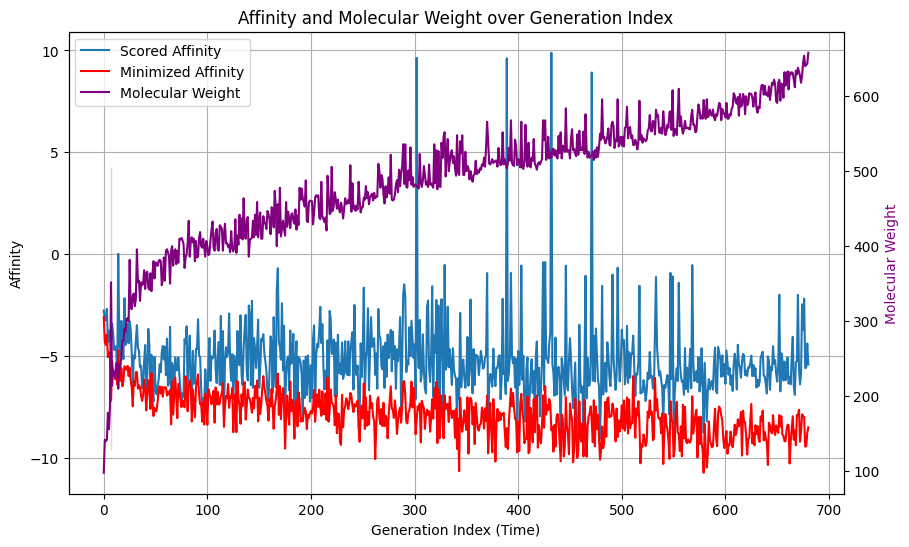

time: 1.58 s (started: 2025-12-14 23:29:06 +00:00)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Create a copy to avoid modifying the original dataframe view
plot_df = df_aff.copy()

# Extract the generation index from the 'sdf' filename column
# Filenames are like '0.sdf', '1.sdf', etc.
plot_df['generation_index'] = plot_df['sdf'].apply(lambda x: int(re.findall(r"(\d+)", x)[0]) if re.findall(r"(\d+)", x) else -1)

# Filter out the reference ligand (which might have index -1 or specific name)
plot_df = plot_df[plot_df['generation_index'] >= 0].sort_values('generation_index')

# Plot setup
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Affinities on the primary (left) y-axis
sns.lineplot(data=plot_df, x='generation_index', y='scored_affinity', ax=ax1, label='Scored Affinity')
sns.lineplot(data=plot_df, x='generation_index', y='minimized_affinity', ax=ax1, color='red', label='Minimized Affinity')
ax1.set_xlabel('Generation Index (Time)')
ax1.set_ylabel('Affinity', color='black')
ax1.grid(True)

# Plot Molecular Weight on the secondary (right) y-axis
ax2 = ax1.twinx()
sns.lineplot(data=plot_df, x='generation_index', y='mol_wt', ax=ax2, color='purple', label='Molecular Weight')
ax2.set_ylabel('Molecular Weight', color='purple')

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

# Remove separate legend for ax2 if it exists
if ax2.get_legend():
    ax2.get_legend().remove()

plt.title('Affinity and Molecular Weight over Generation Index')
plt.show()

In [ ]:
#@title View molecules with mols2grid
!pip install mols2grid --quiet
import mols2grid

# Display the dataframe as an interactive grid of molecules
# We use the 'smiles' column for the structure and show affinity scores
mols2grid.display(df_aff,
                  smiles_col="smiles",
                  subset=["sdf", "minimized_affinity", "mol_wt"],
                  tooltip=["smiles", "scored_affinity", "minimized_affinity", "mol_wt"])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.1/83.1 kB 2.9 MB/s eta 0:00:00


time: 6.19 s (started: 2025-12-14 23:29:32 +00:00)


The molecules generated by deep learning models like Pocket2Mol often look "crude" (e.g., weird rings, long carbon chains, or tiny fragments) because the model optimizes for mathematical probability rather than "medicinal chemistry intuition."

Often, the molecule with the best GNINA score is just a small fragment that fits deeply into a hole, rather than a full drug-like molecule.

Here are three solutions to fix this, ordered from easiest to most effective.

**Solution 1: Filter the Results (Highly Recommended)**

Instead of just taking the molecule with the best score, you should calculate chemical properties (like Molecular Weight) for all 100+ generated molecules and filter out the bad ones before sorting.

Paste this code cell right before you run the "Visualize top hit" cell. It uses RDKit to calculate properties and filters for "drug-like" candidates.

In [ ]:
from rdkit.Chem import Descriptors, QED
import pandas as pd

# 1. Calculate properties for every generated molecule
def get_properties(row):
    # FIX: Use SMILES to create the molecule object.
    # This is safer than file paths because the reference ligand file is in a different folder.
    mol = Chem.MolFromSmiles(row['smiles'])

    if mol:
        mw = Descriptors.MolWt(mol)
        logp = Descriptors.MolLogP(mol)
        qed = QED.qed(mol)
        return pd.Series([mw, logp, qed])
    else:
        return pd.Series([0.0, 0.0, 0.0])

# Add columns to your dataframe
df_aff[['MW', 'LogP', 'QED']] = df_aff.apply(get_properties, axis=1)

# 2. Filter the dataframe
# Keep only molecules that are:
# - Heavier than 300 Daltons (removes tiny fragments)
# - Not too heavy (>600 is usually bad)
# - Have a decent Drug-likeness score (QED > 0.4)
df_filtered = df_aff[
    (df_aff['MW'] > 200) &
    (df_aff['MW'] < 600) &
    (df_aff['QED'] > 0.45)
].copy()

print(f"Original molecules: {len(df_aff)}")
print(f"Molecules after filtering for complexity: {len(df_filtered)}")

# 3. Sort the FILTERED list by Affinity
if len(df_filtered) > 0:
    top_hit = df_filtered.sort_values("minimized_affinity").iloc[0]
    print(f"Best complex molecule: {top_hit.sdf} (Affinity: {top_hit.minimized_affinity}, MW: {top_hit.MW:.1f})")
else:
    print("No molecules met the criteria. Try lowering the QED threshold or generating more samples.")

Original molecules: 682
Molecules after filtering for complexity: 21
Best complex molecule: 128.sdf (Affinity: -8.74382, MW: 391.3)
time: 1.74 s (started: 2025-12-14 23:32:15 +00:00)


### **Step 5: Visualization**
We sort the generated molecules by their binding affinity and display the best one using **Py3DMol**.
* **Cartoon:** The protein ribbon structure.
* **Stick:** The newly generated drug candidate.

# Visualise top hits with Py3DMol

In [ ]:
!pip install py3dmol --upgrade

time: 4.86 s (started: 2025-12-14 23:31:00 +00:00)


In [ ]:
top_hit = df_aff.sort_values("minimized_affinity").loc[lambda df: ~df.sdf.str.contains("_ligand")].iloc[0]
display(pd.DataFrame(top_hit))
top_sdf_file = f'{output_dir}/SDF/{top_hit.sdf}'

,498
pdb,7NN0.pdb
sdf,579.sdf
smiles,NC(=O)C1OCCOC2OC(OC(O)C(O)OCCc3n[nH]c(O)c3O1)C...
scored_affinity,-8.77369
minimized_affinity,-10.73476
mol_wt,595.045184
scored_lig_eff,-0.014745
minimized_lig_eff,-0.014745
MW,595.3
LogP,-3.5888


time: 10.5 ms (started: 2025-12-14 23:32:29 +00:00)


In [ ]:
import py3Dmol
import ipywidgets as widgets
from IPython.display import display

label_text_size = 12

# Updated hover function with dynamic font size
resid_hover = f"""
function(atom,viewer) {{
    if(!atom.label) {{
        atom.label = viewer.addLabel(atom.chain+" "+atom.resn+" "+atom.resi,
            {{position: atom, backgroundColor: 'mintcream', fontColor:'black', fontSize:{label_text_size}}});
    }}
}}"""
unhover_func = """
function(atom,viewer) {
    if(atom.label) {
        viewer.removeLabel(atom.label);
        delete atom.label;
    }
}"""

# Prepare dropdown options from the dataframe
# Filter out the reference ligand file to focus on generated ones
generated_df = df_aff[~df_aff['sdf'].str.contains("_ligand")].sort_values("minimized_affinity")

dropdown_options = []
for _, row in generated_df.iterrows():
    # Create a descriptive label for the dropdown
    label = f"{row['sdf']} | Aff: {row['minimized_affinity']:.2f} | MW: {row['mol_wt']:.1f}"
    dropdown_options.append((label, row['sdf']))

ligand_selector = widgets.Dropdown(
    options=dropdown_options,
    description='Select Ligand:',
    style={'description_width': 'initial'},
    layout={'width': '500px'}
)

def display_ligand(sdf_filename):
    view = py3Dmol.view(width=1000, height=1000)
    view.setBackgroundColor('white') # Set background color
    view.setCameraParameters({'fov': 35, 'z': 100});

    # Add Protein (Model 0)
    view.addModel(open(pdb_file).read(), "pdb");
    view.setStyle({"model": 0}, {"cartoon":{"color":"white"}}) # Set protein color to white
    view.setStyle({"model": 0, "hetflag":True}, {'stick':{"color":"spectrum"}})

    # Highlight specific residue B VXG 701 with magenta carbons as requested
    view.addStyle({"model": 0, "chain": "B", "resn": "VXG", "resi": "701"},
                  {'stick': {'colorscheme': 'magentaCarbon'}})

    # Define selection for residues within 15A of the original ligand pocket
    # Updated model index to 0
    nearby_residues_sel = {'model': 0, 'hetflag': False, 'within': {'distance': 15, 'sel': {'resn': LIG_ID}}}

    # Add VDW surface of protein near pocket
    view.addSurface(py3Dmol.VDW, {'opacity': 0.9}, nearby_residues_sel)

    # Show nearby residues as sticks
    view.addStyle(nearby_residues_sel, {'stick': {}})

    # Add residue labels
    view.addResLabels(nearby_residues_sel, {'backgroundColor': 'white', 'fontColor': 'black', 'backgroundOpacity': 0, 'fontSize': label_text_size})

    # Add Selected Generated Ligand (Model 1)
    sdf_path = f"{output_dir}/SDF/{sdf_filename}"
    try:
        view.addModel(open(sdf_path).read(), "sdf")
        # Set generated ligand carbons to Yellow (Model 1)
        view.setStyle({"model": 1}, {'stick':{"colorscheme": "yellowCarbon"}})
        view.setViewStyle({"model": 1}, {'style':'outline','color':'black','width':0.1})
        view.zoomTo();
    except Exception as e:
        print(f"Error loading ligand file {sdf_path}: {e}")

    # Enable hover labels on the protein (Model 0)
    # We access Model 0 explicitly to ensure hover works on residues
    model = view.getModel(0)
    model.setHoverable({}, True, resid_hover, unhover_func)

    view.show()

# Interactive widget
print("Select a generated ligand to visualize:")
widgets.interact(display_ligand, sdf_filename=ligand_selector);

Select a generated ligand to visualize:


interactive(children=(Dropdown(description='Select Ligand:', layout=Layout(width='500px'), options=(('579.sdf …

time: 98.3 ms (started: 2025-12-14 23:32:46 +00:00)


### **Step 6: Interaction Analysis**
Finally, we use **ProLIF** to generate a 2D interaction diagram. This shows exactly which amino acids in the protein are "touching" our new molecule (e.g., via Hydrogen bonds or Hydrophobic contacts).

In [ ]:
!pip install prolif --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 86.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 4.9 MB/s eta 0:00:00
time: 9.98 s (started: 2025-12-11 12:37:58 +00:00)


In [ ]:

import prolif as plf
from prolif.plotting.network import LigNetwork
from rdkit import Chem
import ipywidgets as widgets
from IPython.display import display

# load protein
prot = Chem.MolFromPDBFile(pdb_file, removeHs=False)
prot = plf.Molecule(prot)

# Prepare dropdown options from the dataframe
generated_df = df_aff[~df_aff['sdf'].str.contains("_ligand")].sort_values("minimized_affinity")

dropdown_options = []
for _, row in generated_df.iterrows():
    # Create a descriptive label for the dropdown
    label = f"{row['sdf']} | Aff: {row['minimized_affinity']:.2f} | MW: {row['mol_wt']:.1f}"
    dropdown_options.append((label, row['sdf']))

ligand_selector = widgets.Dropdown(
    options=dropdown_options,
    description='Select Ligand:',
    style={'description_width': 'initial'},
    layout={'width': '500px'}
)

def display_prolif(sdf_filename):
    sdf_path = f"{output_dir}/SDF/{sdf_filename}"

    # load ligand
    lig_suppl = list(plf.sdf_supplier(sdf_path))

    # generate fingerprint
    fp = plf.Fingerprint()
    fp.run_from_iterable(lig_suppl, prot)

    # Generate and display network
    # kind="frame", frame=0 ensures we look at the specific conformation in the SDF
    net = LigNetwork.from_fingerprint(fp, lig_suppl[0], kind="frame", frame=0, rotation=0)
    return net.display()

print("Select a generated ligand to visualize in ProLIF:")
widgets.interact(display_prolif, sdf_filename=ligand_selector);

/usr/local/lib/python3.12/dist-packages/MDAnalysis/topology/tables.py:52: DeprecationWarning: Deprecated in version 2.8.0
MDAnalysis.topology.tables has been moved to MDAnalysis.guesser.tables. This import point will be removed in MDAnalysis version 3.0.0
  warnings.warn(wmsg, category=DeprecationWarning)


Select a generated ligand to visualize in ProLIF:


interactive(children=(Dropdown(description='Select Ligand:', layout=Layout(width='500px'), options=(('641.sdf …

time: 2.64 s (started: 2025-12-11 12:38:12 +00:00)


**Solution 2: Increase Sample Size**

*Since you are now filtering out the "crude" molecules, you might run out of candidates. You should increase the number of molecules you generate so that after filtering, you still have good options.

* Find this cell: `!python sample_for_pdb.py ...`
Change: `--num_samples 100 $\to$ --num_samples 500`


This will take 5x longer to run, but it statistically guarantees you will find a more complex, high-affinity binder.

**Solution 3: Adjust the "Bounding Box"**

If your generated molecules are consistently too small, the model might be confined to too small a box around the pocket center.

Find this cell: `!python sample_for_pdb.py ...`

Add this flag: `--bbox_size 30` (The default is usually around 23 Angstroms. Increasing this gives the model more space to build a larger molecule).